# 13. Conclusions: the models we keep

What the forecast (nb 12) uses, where each number comes from, and the one plot that shows it. Nothing is fitted here: the plots are read from the notebooks named next to them.

0. Conclusions we didn't prove
1. The mission (nb 04)
2. The Starlink plan (nb 05)
3. Solar: our forecast (nb 10)
4. The energy balance: hotel, Starlink, motor (nb 06, nb 08)
5. Battery (nb 11)
6. How good it is (nb 12)
7. Assumptions and open hypotheses

## 0. Conclusions we didn't prove

Decisions we take as true without a test. Same order as the sections below; source notebook in brackets.

**1. Mission**

**2. Starlink plan**

**3. Solar**

**4. Energy balance**
- battery1 voltage and battery2 voltage are the same measurement (nb 01)

**5. Battery**


In [1]:
import base64, json
import pandas as pd
from IPython.display import Image, display

def show_fig(notebook, cell_id, n=0):
    """Show the n-th plot saved in a cell of another notebook (as it was last run there)."""
    cell = next(c for c in json.load(open(notebook))["cells"] if c.get("id") == cell_id)
    pngs = [o["data"]["image/png"] for o in cell.get("outputs", []) if "image/png" in o.get("data", {})]
    display(Image(base64.b64decode(pngs[n])))

## 1. The mission (nb 04)

What the boat was told to do: **one line per change of mode or arming (95)**, **plus 10 speed steps** inside motor-on lines, so **105 lines**, 14 Jul 00:20 to 30 Jul 23:42. Every change counts as a command, even short blips.

- **AUTO, mode 17:** motor on, at the line's speed (median speed over ground of the line)
- **MANUAL** (armed or disarmed): motor off

**Speed steps:** a motor-on line is split where its speed clearly changes level (medians ≥ 0.3 m/s apart, pieces ≥ 20 min). This took the load error from 19.0 to 16.1 W with k·v (16.8 W with k·v², nb 08). The split lines:

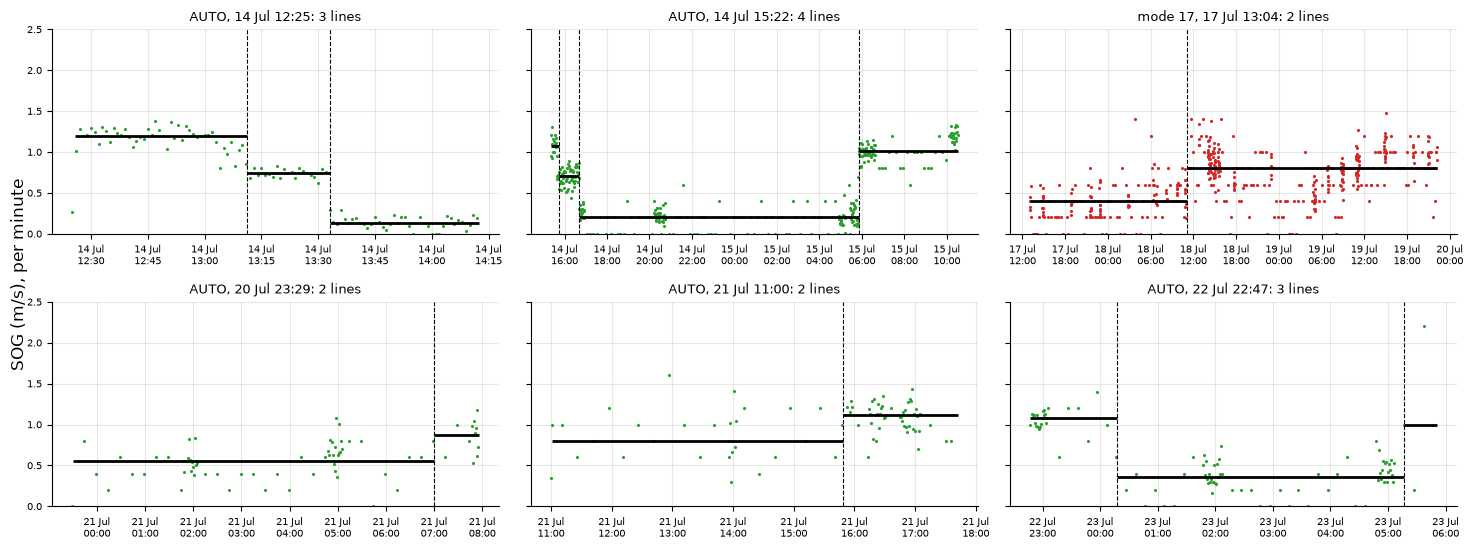

In [2]:
show_fig("04_mission.ipynb", "ea08ee21")

In [3]:
pd.set_option("display.max_rows", 200)
mission = pd.read_csv("../data/mission_modes.csv", parse_dates=["from", "to"], index_col="#")
mission

,from,to,hours,mode,armed,new because,seen within (min),via,lat,lon,wp lat,wp lon,SOG (m/s)
#,,,,,,,,,,,,,
1,2025-07-14 00:20:51+00:00,2025-07-14 07:48:57+00:00,7.469,MANUAL,False,mode/arming,NaN,Iridium+Starlink,60.12823,2.21624,60.12756,2.19595,0.02
2,2025-07-14 07:48:57+00:00,2025-07-14 08:23:16+00:00,0.572,MANUAL,True,mode/arming,0.21,Starlink,60.39253,2.13578,60.12756,2.19595,0.04
3,2025-07-14 08:23:16+00:00,2025-07-14 08:23:35+00:00,0.005,AUTO,True,mode/arming,0.02,Starlink,60.39249,2.13573,60.12756,2.19595,0.06
4,2025-07-14 08:23:35+00:00,2025-07-14 09:36:16+00:00,1.211,MANUAL,True,mode/arming,0.25,Iridium+Starlink,60.39249,2.13573,60.12756,2.19595,0.05
5,2025-07-14 09:36:16+00:00,2025-07-14 10:13:17+00:00,0.617,MANUAL,False,mode/arming,0.02,Iridium+Starlink,60.38984,2.13889,60.12756,2.19595,1.91
6,2025-07-14 10:13:17+00:00,2025-07-14 10:29:55+00:00,0.277,MANUAL,True,mode/arming,0.03,Starlink,60.35899,2.12499,60.12756,2.19595,0.74
7,2025-07-14 10:29:55+00:00,2025-07-14 10:31:30+00:00,0.026,AUTO,True,mode/arming,0.02,Starlink,60.35186,2.11895,60.35090,2.11877,0.72
8,2025-07-14 10:31:30+00:00,2025-07-14 10:32:15+00:00,0.013,MANUAL,True,mode/arming,0.25,Starlink,60.35133,2.11862,60.35090,2.11877,0.59
9,2025-07-14 10:32:15+00:00,2025-07-14 10:35:15+00:00,0.050,AUTO,True,mode/arming,0.25,Starlink,60.35118,2.11849,60.35143,2.11875,1.21


## 2. The Starlink plan (nb 05)

We just followed the Starlink plan: **every Starlink session** is in it, scheduled (wakes at hh:47, every 2 h then every 3 h), extra (switched on from shore) and the deployment phase. Each session is an on-window, first to last message ± 30 s. Off after 27 Jul 02:05.

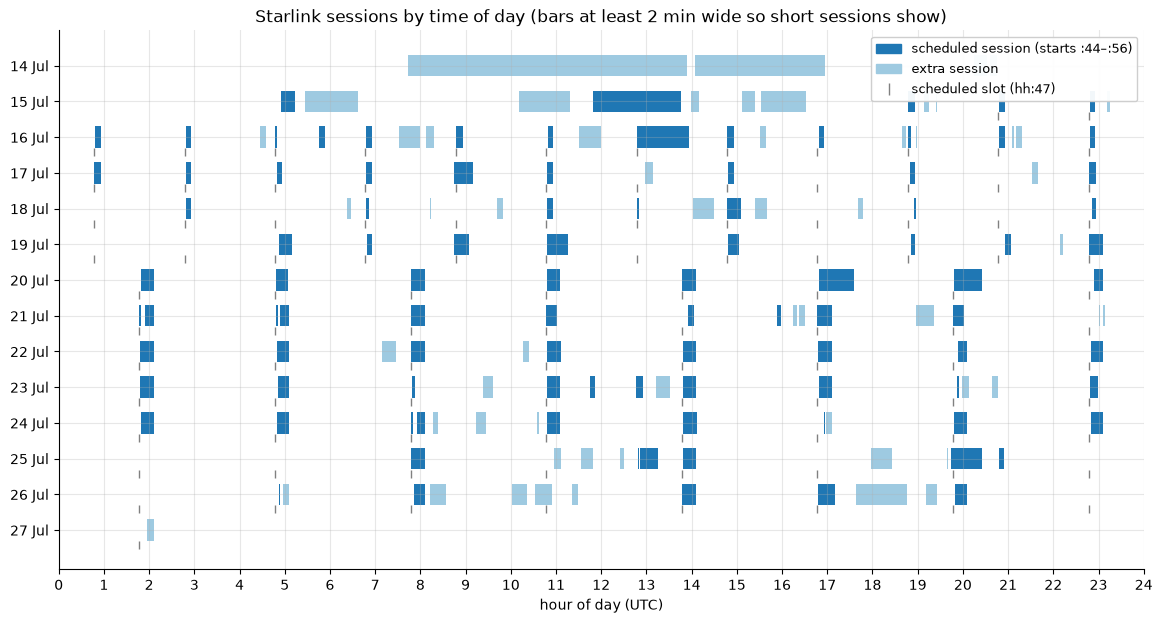

,sessions,hours
kind,,
deployment,14,16.0
extra,49,10.1
scheduled,96,22.5


In [4]:
show_fig("05_comms_schedule.ipynb", "8c6674fb")
sl = pd.read_csv("../data/mission_starlink.csv", parse_dates=["from", "to"])
sl.assign(hours=(sl.to - sl["from"]).dt.total_seconds() / 3600).groupby("kind").hours.agg(sessions="size", hours="sum").round(1)

## 3. Solar: our forecast (nb 10)

**P_solar(t) = peak_day · cos(π · (t − 12.7 h) / 24 h)^5.5**, 0 at night (t = UTC hour). One shape for all days, one peak per day (52–172 W; 100 W on days with no data).

This is the solar forecast. Positions and dates are shifted, so there is no weather forecast to compare with: we take these daily curves as the forecast.

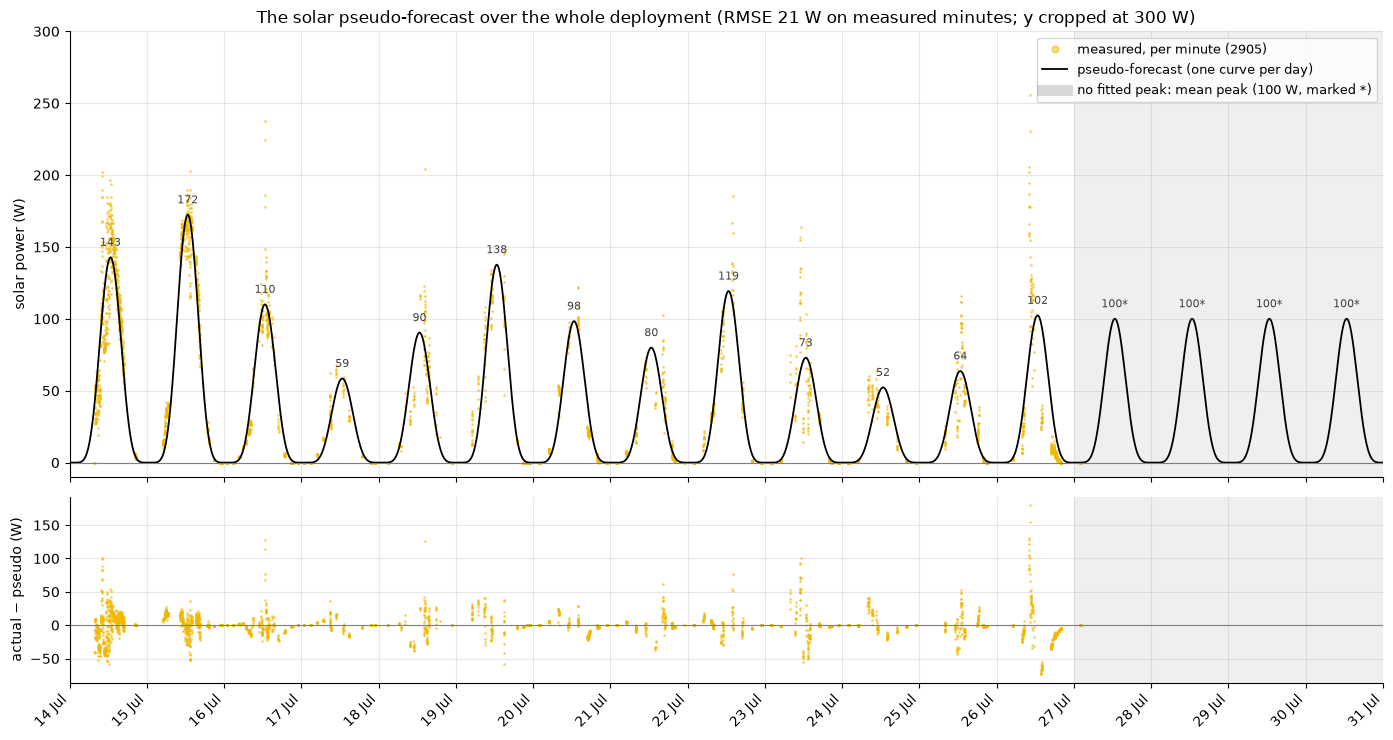

In [5]:
show_fig("10_solar_model.ipynb", "be753e63")

## 4. The energy balance

Every minute:

**P_net = η · P_solar − P_load − P_drain**, **OCV += P_net · Δt / k**, **V = OCV + R · P_net / V**, no charging above 25.0 V.

**P_load = P_hotel + P_starlink · Starlink + k_mode · v_line²**

| term | value | from |
| --- | --- | --- |
| P_hotel | 10 W | 4.1 |
| P_starlink | 22 W | 4.2 |
| Starlink | 0–1 | the plan (section 2) |
| k_mode | AUTO 62.7, mode 17 60.6, MANUAL 0 W per (m/s)² | 4.3 |
| v_line | m/s | the mission (section 1) |

### 4.1 Hotel: 10 W (nb 06)

In MANUAL the load doesn't change with speed, so the motor is off. What's left with Starlink off is the hotel load: **~10 W** (orange, first two panels). It moves between ~5 and 15 W over a day.

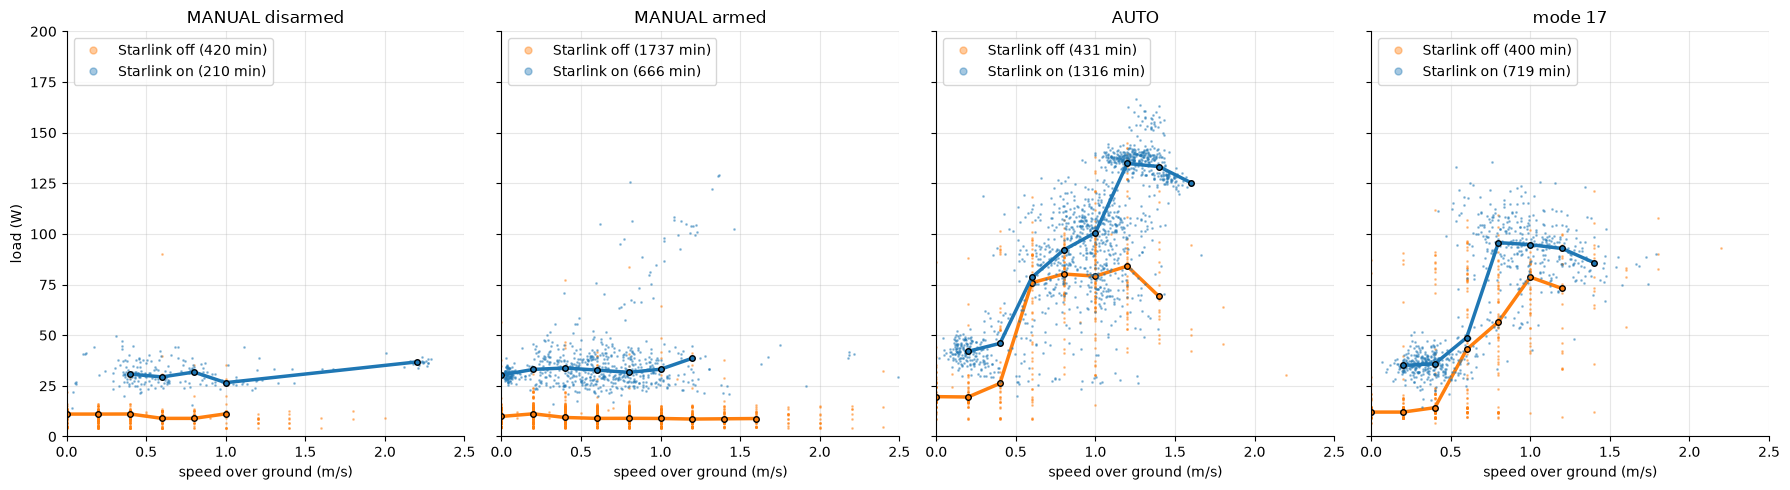

In [6]:
show_fig("06_comms_and_hotel.ipynb", "dc3481ea")

### 4.2 Starlink: 22 W (nb 06)

From **MANUAL only** (motor off): Starlink on minus off = 21 W disarmed, 23 W armed. AUTO and mode 17 are in the plot too, but there on minus off (33 and 40 W) also holds a motor difference, so they can't give the Starlink power alone. Anything that switches on with Starlink is counted in here.

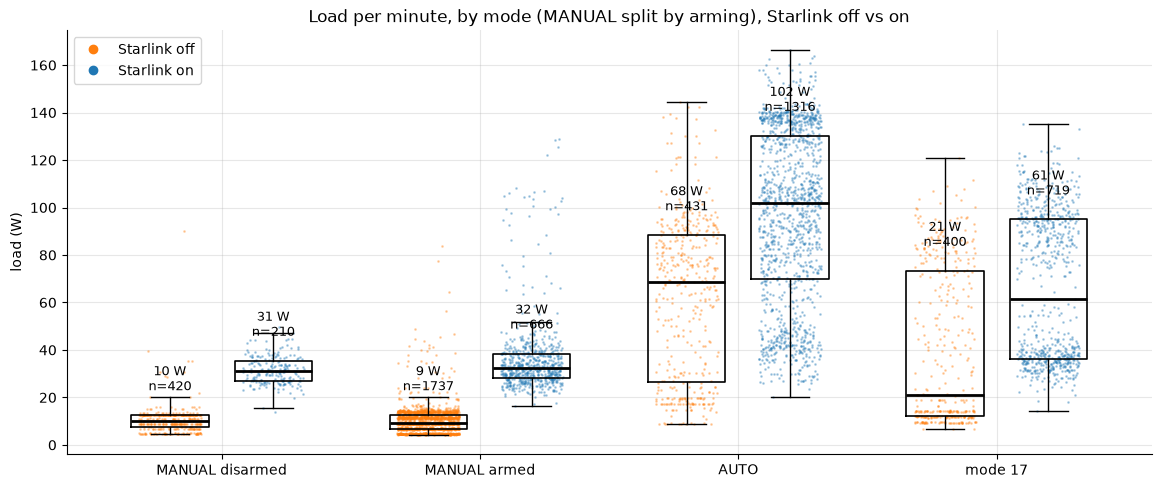

In [7]:
show_fig("06_comms_and_hotel.ipynb", "793435ce")

### 4.3 Motor: k_mode · v_line² (nb 08)

Propulsion = load − 10 − 22·Starlink, against the speed of the mission line, motor-on minutes only, no intercept. One k per mode, **k·v² for both**: **AUTO 62.7 ± 0.5**, **mode 17 60.6 ± 0.9 W per (m/s)²**. k·v² fits mode 17 best (R² per line 0.85 vs 0.79 for k·v); in AUTO k·v fits slightly better (0.75 vs 0.66), but we use k·v² for both.

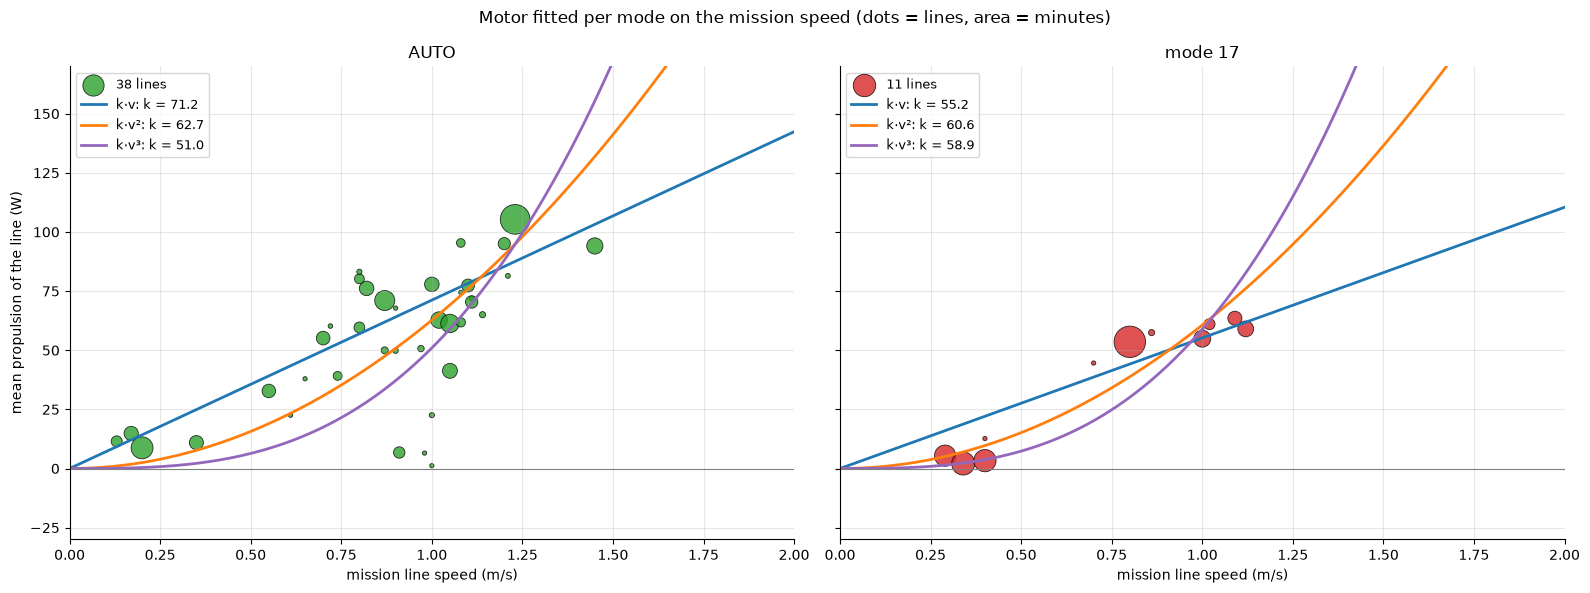

In [8]:
show_fig("08_load_vs_mission.ipynb", "5517a1b0")

## 5. Battery (nb 11), model B1

| parameter | value |
| --- | --- |
| k | 420 ± 31 Wh per V |
| η | 1.14 ± 0.07 (> 1: a sensor scale factor, not an efficiency) |
| P_drain | −0.3 ± 2.1 W |
| R | 39.2 mΩ, measured separately and fixed |
| V_cap | 25.0 V |

Free run with measured solar and load, never corrected: **RMSE 0.40 V**.

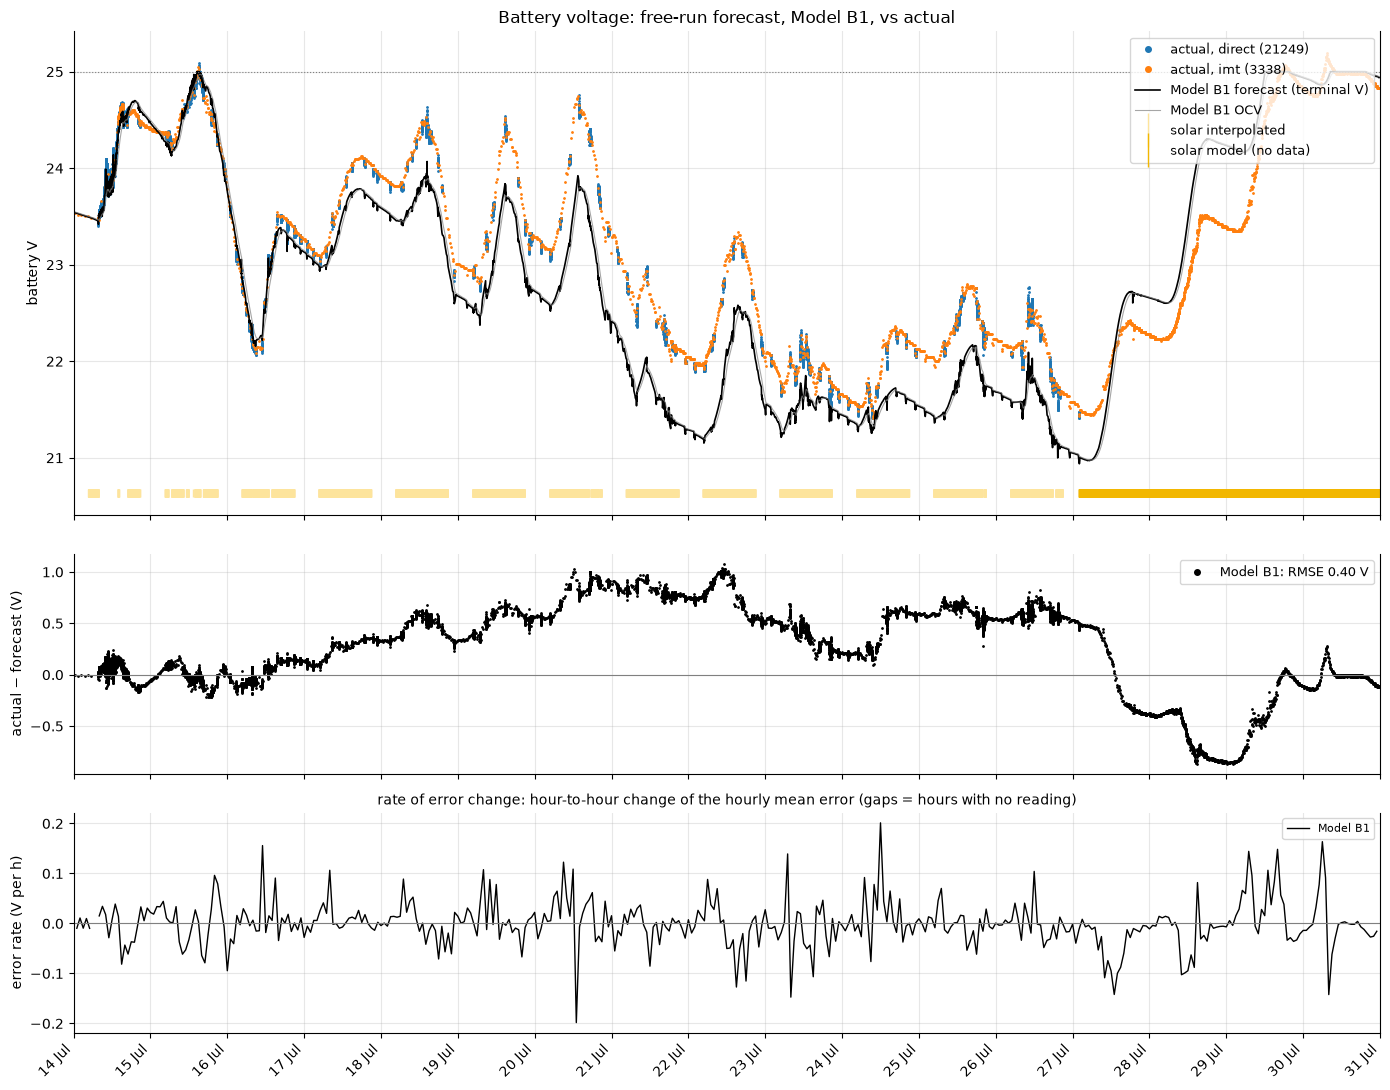

In [9]:
show_fig("11_capacity_model.ipynb", "14d22125")

## 6. How good it is (nb 12)

| run | solar | load | 24 h pieces: mean \|end error\| (to 27 Jul) | 17 days, free run: RMSE |
| --- | --- | --- | --- | --- |
| **forecast** | forecast | mission + plan | 0.36 V | 0.95 V |
| perfect solar | measured | mission + plan | 0.32 V | 0.97 V |
| perfect load | forecast | measured | 0.23 V | 0.66 V |
| both measured | measured | measured | 0.16 V | 0.40 V |

- Solar energy matches (11.55 vs 11.54 kWh to 27 Jul).
- The load is ~1.1 kWh too low to 27 Jul (11.61 vs 12.69 kWh); in the free run the forecast ends up too high, daily mean error down to −2.4 V (27 Jul).
- All models were fitted on the same 17 days we forecast.

## 7. Assumptions and open hypotheses

**Assumptions:** every mode or arming change is a command; the daily solar curves are the forecast; MANUAL = motor off; the line speed is the commanded speed; hotel and Starlink are locked.

**Hypotheses:**
- **Below ~0.4 m/s the speed is drift, not the motor.** *Test:* motor = 0 for lines under 0.4 m/s, refit k per mode (nb 08), rerun nb 12.
- **The models hold on days they weren't fitted on.** *Test:* fit on 14–22 Jul, forecast 23–30 Jul.
- **η > 1 is a sensor scale error.** *Test:* fit k and η on long windows only and check η drops to ~1.